# 🔬 Stomata Detection - YOLOv8 Training v4


## Training Strategy: Two Classes, Count One

**How it works:**
- ✅ Train on **BOTH** classes: `stomata` + `artifact`
- ✅ Model learns to **distinguish** real stomata from debris
- ✅ Preview shows: **GREEN = Stomata**, **MAGENTA = Artifact**
- ✅ Final count: **Only stomata** (artifacts filtered out)

---

⚠️ **Run cells in order with Shift + Enter**

---
## 🚀 Step 1: Setup Environment

In [ ]:
# Check GPU
!nvidia-smi

# Install packages
!pip install ultralytics roboflow pyyaml -q

# Imports
import os
import shutil
import yaml
from datetime import datetime
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import numpy as np
from IPython.display import Image, display

print("\n" + "="*50)
print("✅ Setup complete!")
print(f"📅 {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print("="*50)

Fri Feb 13 21:47:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

---
## 💾 Step 2: Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

SAVE_DIR = '/content/drive/MyDrive/Stomata_Models_V5.1'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"✅ Models will be saved to: {SAVE_DIR}")

✅ Models will be saved to: /content/drive/MyDrive/Stomata_Models_V5.1


---
## 📥 Step 3: Download Dataset from Roboflow

### ⚠️ PASTE YOUR ROBOFLOW CODE BELOW

In [ ]:
# ╔════════════════════════════════════════════════════════════════╗
# ║  PASTE YOUR ROBOFLOW CODE HERE                                 ║
# ╚════════════════════════════════════════════════════════════════╝



# REPLACE WITH YOUR CODE:
from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_API_KEY")
project = rf.workspace("stomatal").project("stomata-detection-eezkq")
version = project.version(5)
dataset = version.download("yolov8")




DATASET_PATH = dataset.location
print(f"\n✅ Dataset downloaded to: {DATASET_PATH}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Stomata-Detection-5 in yolov8:: 100%|██████████| 1212/1212 [00:00<00:00, 2913.21it/s]


✅ Dataset downloaded to: /content/Stomata-Detection-5


In [ ]:
# ══════════════════════════════════════════════════════════════════
# READ CLASS NAMES FROM data.yaml
# ══════════════════════════════════════════════════════════════════

yaml_path = os.path.join(DATASET_PATH, 'data.yaml')

with open(yaml_path, 'r') as f:
    data_config = yaml.safe_load(f)

# Get class names as list
CLASS_NAMES = data_config.get('names', [])
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[i] for i in sorted(CLASS_NAMES.keys())]

# Find stomata and artifact indices by name
STOMATA_IDX = None
ARTIFACT_IDX = None

for idx, name in enumerate(CLASS_NAMES):
    name_lower = name.lower()
    if 'stomata' in name_lower or 'stoma' in name_lower:
        STOMATA_IDX = idx
    elif 'artifact' in name_lower or 'bubble' in name_lower or 'debris' in name_lower:
        ARTIFACT_IDX = idx

print("="*60)
print("📊 DATASET INFORMATION")
print("="*60)
print(f"\n📋 Classes found:")
for idx, name in enumerate(CLASS_NAMES):
    if idx == STOMATA_IDX:
        print(f"   🟢 Class {idx}: '{name}' → STOMATA (will be COUNTED)")
    elif idx == ARTIFACT_IDX:
        print(f"   🟣 Class {idx}: '{name}' → ARTIFACT (will be FILTERED OUT)")
    else:
        print(f"   ⚪ Class {idx}: '{name}'")

print(f"\n📁 Dataset splits:")
for split in ['train', 'valid', 'test']:
    path = os.path.join(DATASET_PATH, split, 'images')
    if os.path.exists(path):
        count = len([f for f in os.listdir(path) if f.endswith(('.jpg', '.png'))])
        print(f"   {split}: {count} images")

print("\n" + "="*60)

📊 DATASET INFORMATION

📋 Classes found:
   🟣 Class 0: 'artifact' → ARTIFACT (will be FILTERED OUT)
   🟢 Class 1: 'stomata' → STOMATA (will be COUNTED)

📁 Dataset splits:
   train: 525 images
   valid: 50 images
   test: 25 images



---
## 👁️ Step 4: Preview Training Images

**Color coding:**
- 🟢 **GREEN boxes** = Stomata (will be counted)
- 🟣 **MAGENTA boxes** = Artifacts (will be filtered out)

In [ ]:
import random

def preview_dataset(dataset_path, num_images=4):
    """Preview with CORRECT class colors: GREEN=stomata, MAGENTA=artifact."""
    train_img = os.path.join(dataset_path, 'train', 'images')
    train_lbl = os.path.join(dataset_path, 'train', 'labels')

    all_images = [f for f in os.listdir(train_img) if f.endswith(('.jpg', '.png', '.jpeg'))]
    samples = random.sample(all_images, min(num_images, len(all_images)))

    fig, axes = plt.subplots(2, 2, figsize=(14, 14))
    axes = axes.flatten()

    for idx, img_name in enumerate(samples):
        img = cv2.imread(os.path.join(train_img, img_name))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        lbl_path = os.path.join(train_lbl, os.path.splitext(img_name)[0] + '.txt')

        stomata_count = 0
        artifact_count = 0

        if os.path.exists(lbl_path):
            with open(lbl_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        # READ THE CLASS ID!
                        cls = int(parts[0])
                        x_c, y_c, bw, bh = map(float, parts[1:5])

                        x1 = int((x_c - bw/2) * w)
                        y1 = int((y_c - bh/2) * h)
                        x2 = int((x_c + bw/2) * w)
                        y2 = int((y_c + bh/2) * h)

                        # Draw based on class
                        if cls == STOMATA_IDX:
                            stomata_count += 1
                            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
                        elif cls == ARTIFACT_IDX:
                            artifact_count += 1
                            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 255), 2)
                        else:
                            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 0), 2)

        axes[idx].imshow(img)
        axes[idx].set_title(f'Stomata: {stomata_count} (🟢) | Artifacts: {artifact_count} (🟣)', fontsize=11)
        axes[idx].axis('off')

    plt.suptitle('Training Preview: GREEN=Stomata (counted) | MAGENTA=Artifact (filtered)', fontsize=13)
    plt.tight_layout()
    plt.show()

    print("\n" + "="*60)
    print("PREVIEW LEGEND:")
    print(f"   🟢 GREEN  = {CLASS_NAMES[STOMATA_IDX]} (class {STOMATA_IDX}) → COUNTED")
    print(f"   🟣 MAGENTA = {CLASS_NAMES[ARTIFACT_IDX]} (class {ARTIFACT_IDX}) → FILTERED OUT")
    print("="*60)

preview_dataset(DATASET_PATH)
print("\n✅ Verify: Stomata have GREEN boxes, Artifacts have MAGENTA boxes")

Output hidden; open in https://colab.research.google.com to view.

---
## ⚙️ Step 5: Training Configuration

In [ ]:
MODEL_SIZE = "yolov8s.pt"
EPOCHS = 250
IMAGE_SIZE = 640
BATCH_SIZE = 8
PATIENCE = 75
LEARNING_RATE = 0.0005

print("╔" + "═"*50 + "╗")
print("║         TRAINING CONFIGURATION                   ║")
print("╠" + "═"*50 + "╣")
print(f"║  Model:         {MODEL_SIZE:<32} ║")
print(f"║  Epochs:        {EPOCHS:<32} ║")
print(f"║  Classes:       {', '.join(CLASS_NAMES):<32} ║")
print("╚" + "═"*50 + "╝")

╔══════════════════════════════════════════════════╗
║         TRAINING CONFIGURATION                   ║
╠══════════════════════════════════════════════════╣
║  Model:         yolov8s.pt                       ║
║  Epochs:        250                              ║
║  Classes:       artifact, stomata                ║
╚══════════════════════════════════════════════════╝


---
## 🚂 Step 6: Train the Model

In [ ]:
print("🚀 Starting training...")
print(f"📋 Classes: {CLASS_NAMES}")
print("⏱️  Takes 30-90 minutes\n")

model = YOLO(MODEL_SIZE)

results = model.train(
    data=os.path.join(DATASET_PATH, 'data.yaml'),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    lr0=LEARNING_RATE,
    project='/content/stomata_training',
    name='run',
    exist_ok=True,
    pretrained=True,
    plots=True,
    save=True,
    val=True,
    verbose=True,
    seed=42,
)

print("\n🎉 TRAINING COMPLETE!")

🚀 Starting training...
📋 Classes: ['artifact', 'stomata']
⏱️  Takes 30-90 minutes

Ultralytics 8.4.14 🚀 Python-3.12.12 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Stomata-Detection-5/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=250, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=run, nbs=64, nms=False

---
## 📊 Step 7: View Results

📈 Training Curves:


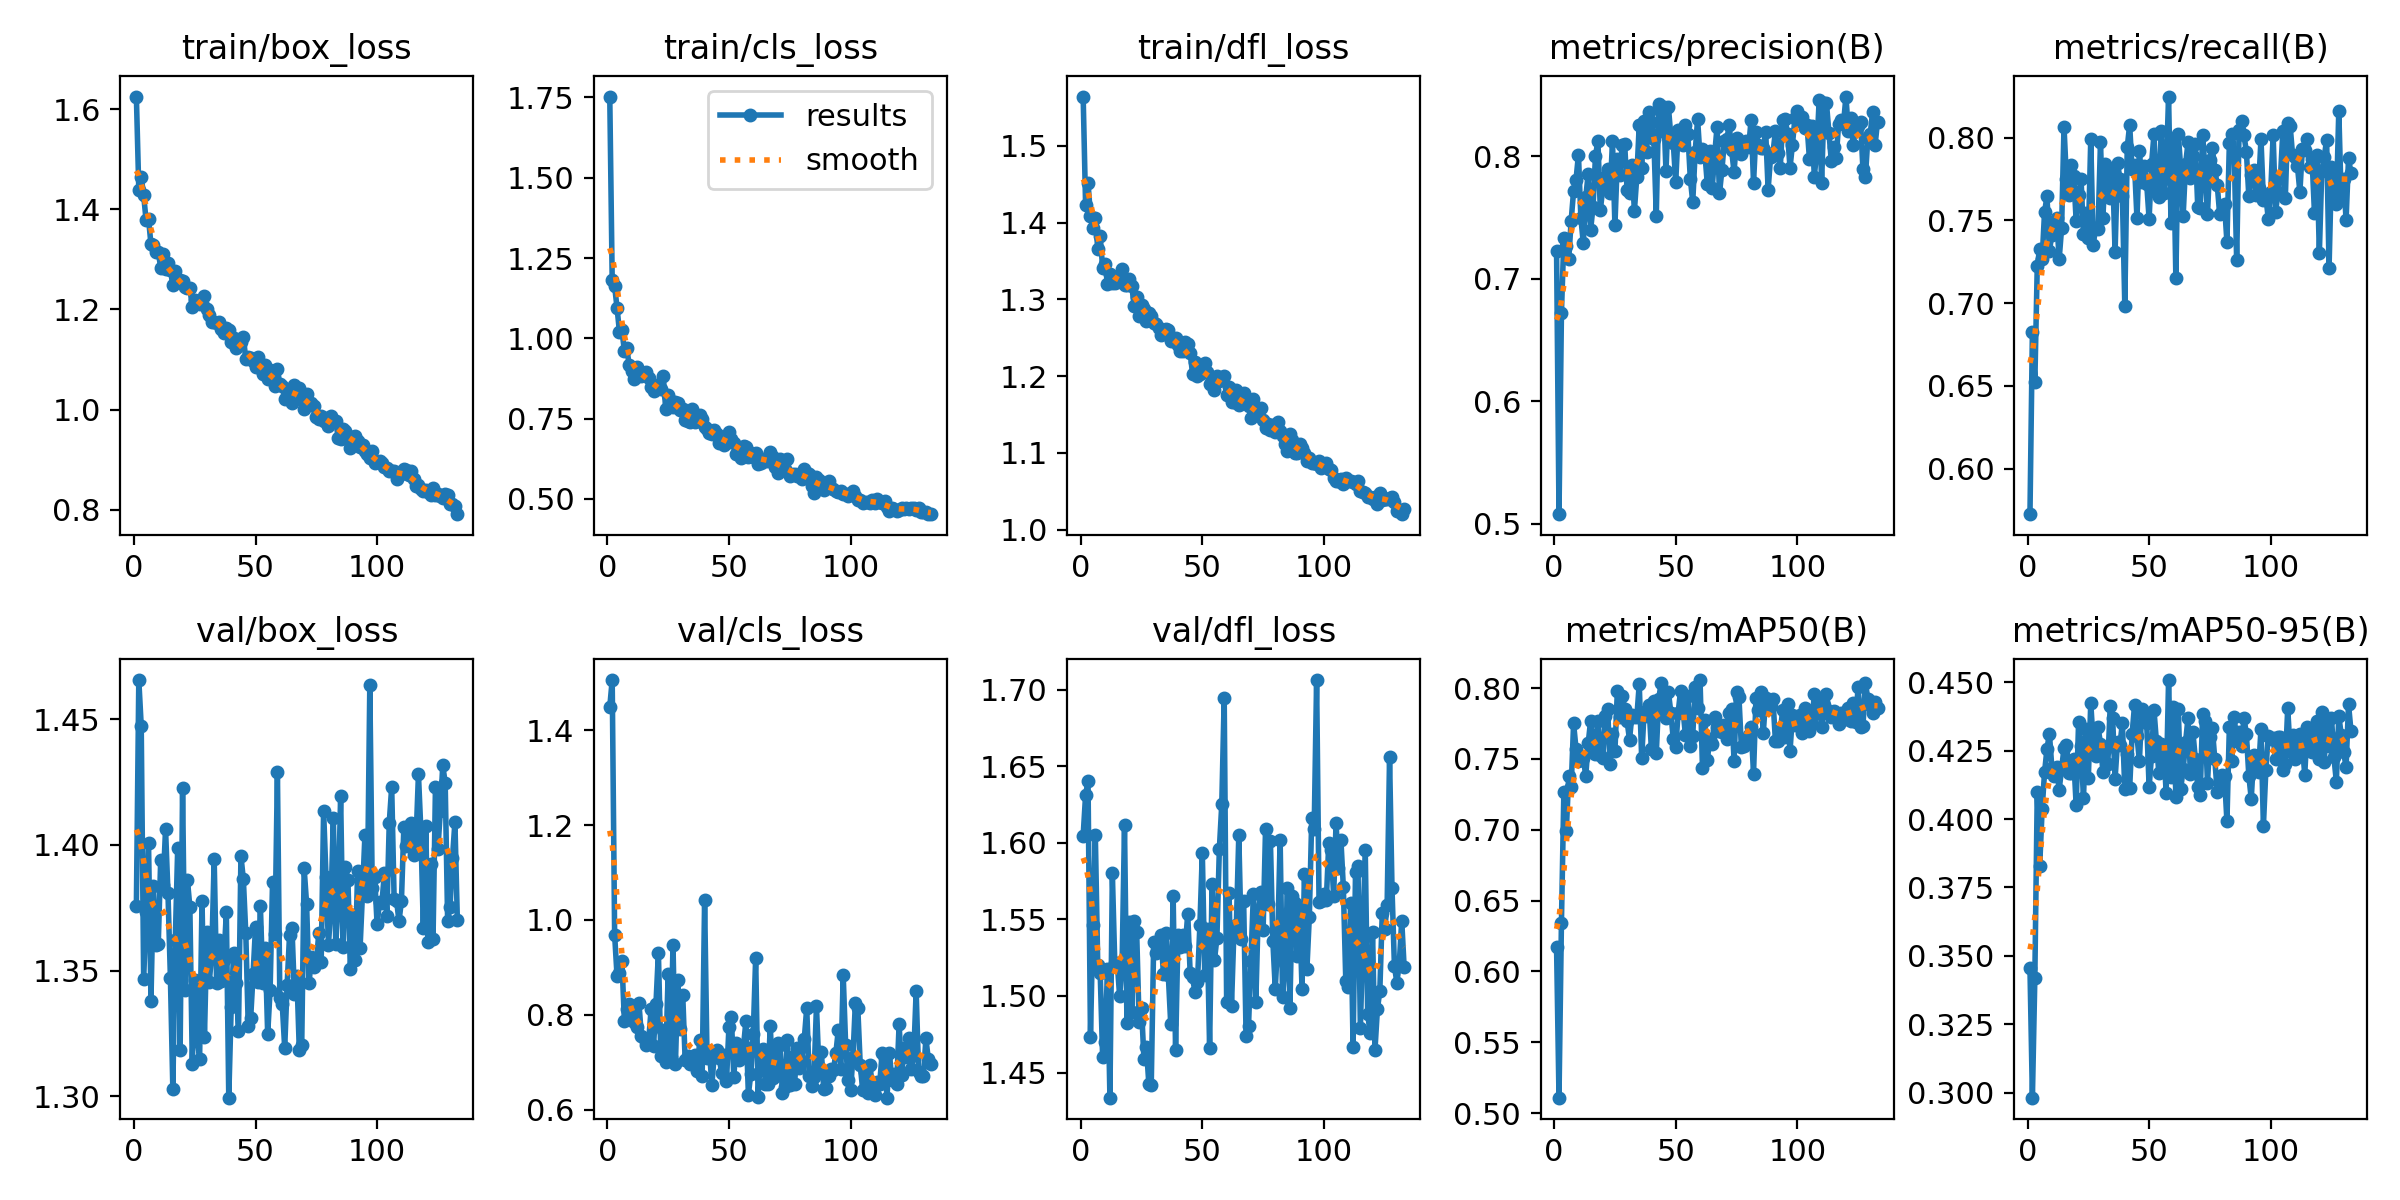


📊 Confusion Matrix:


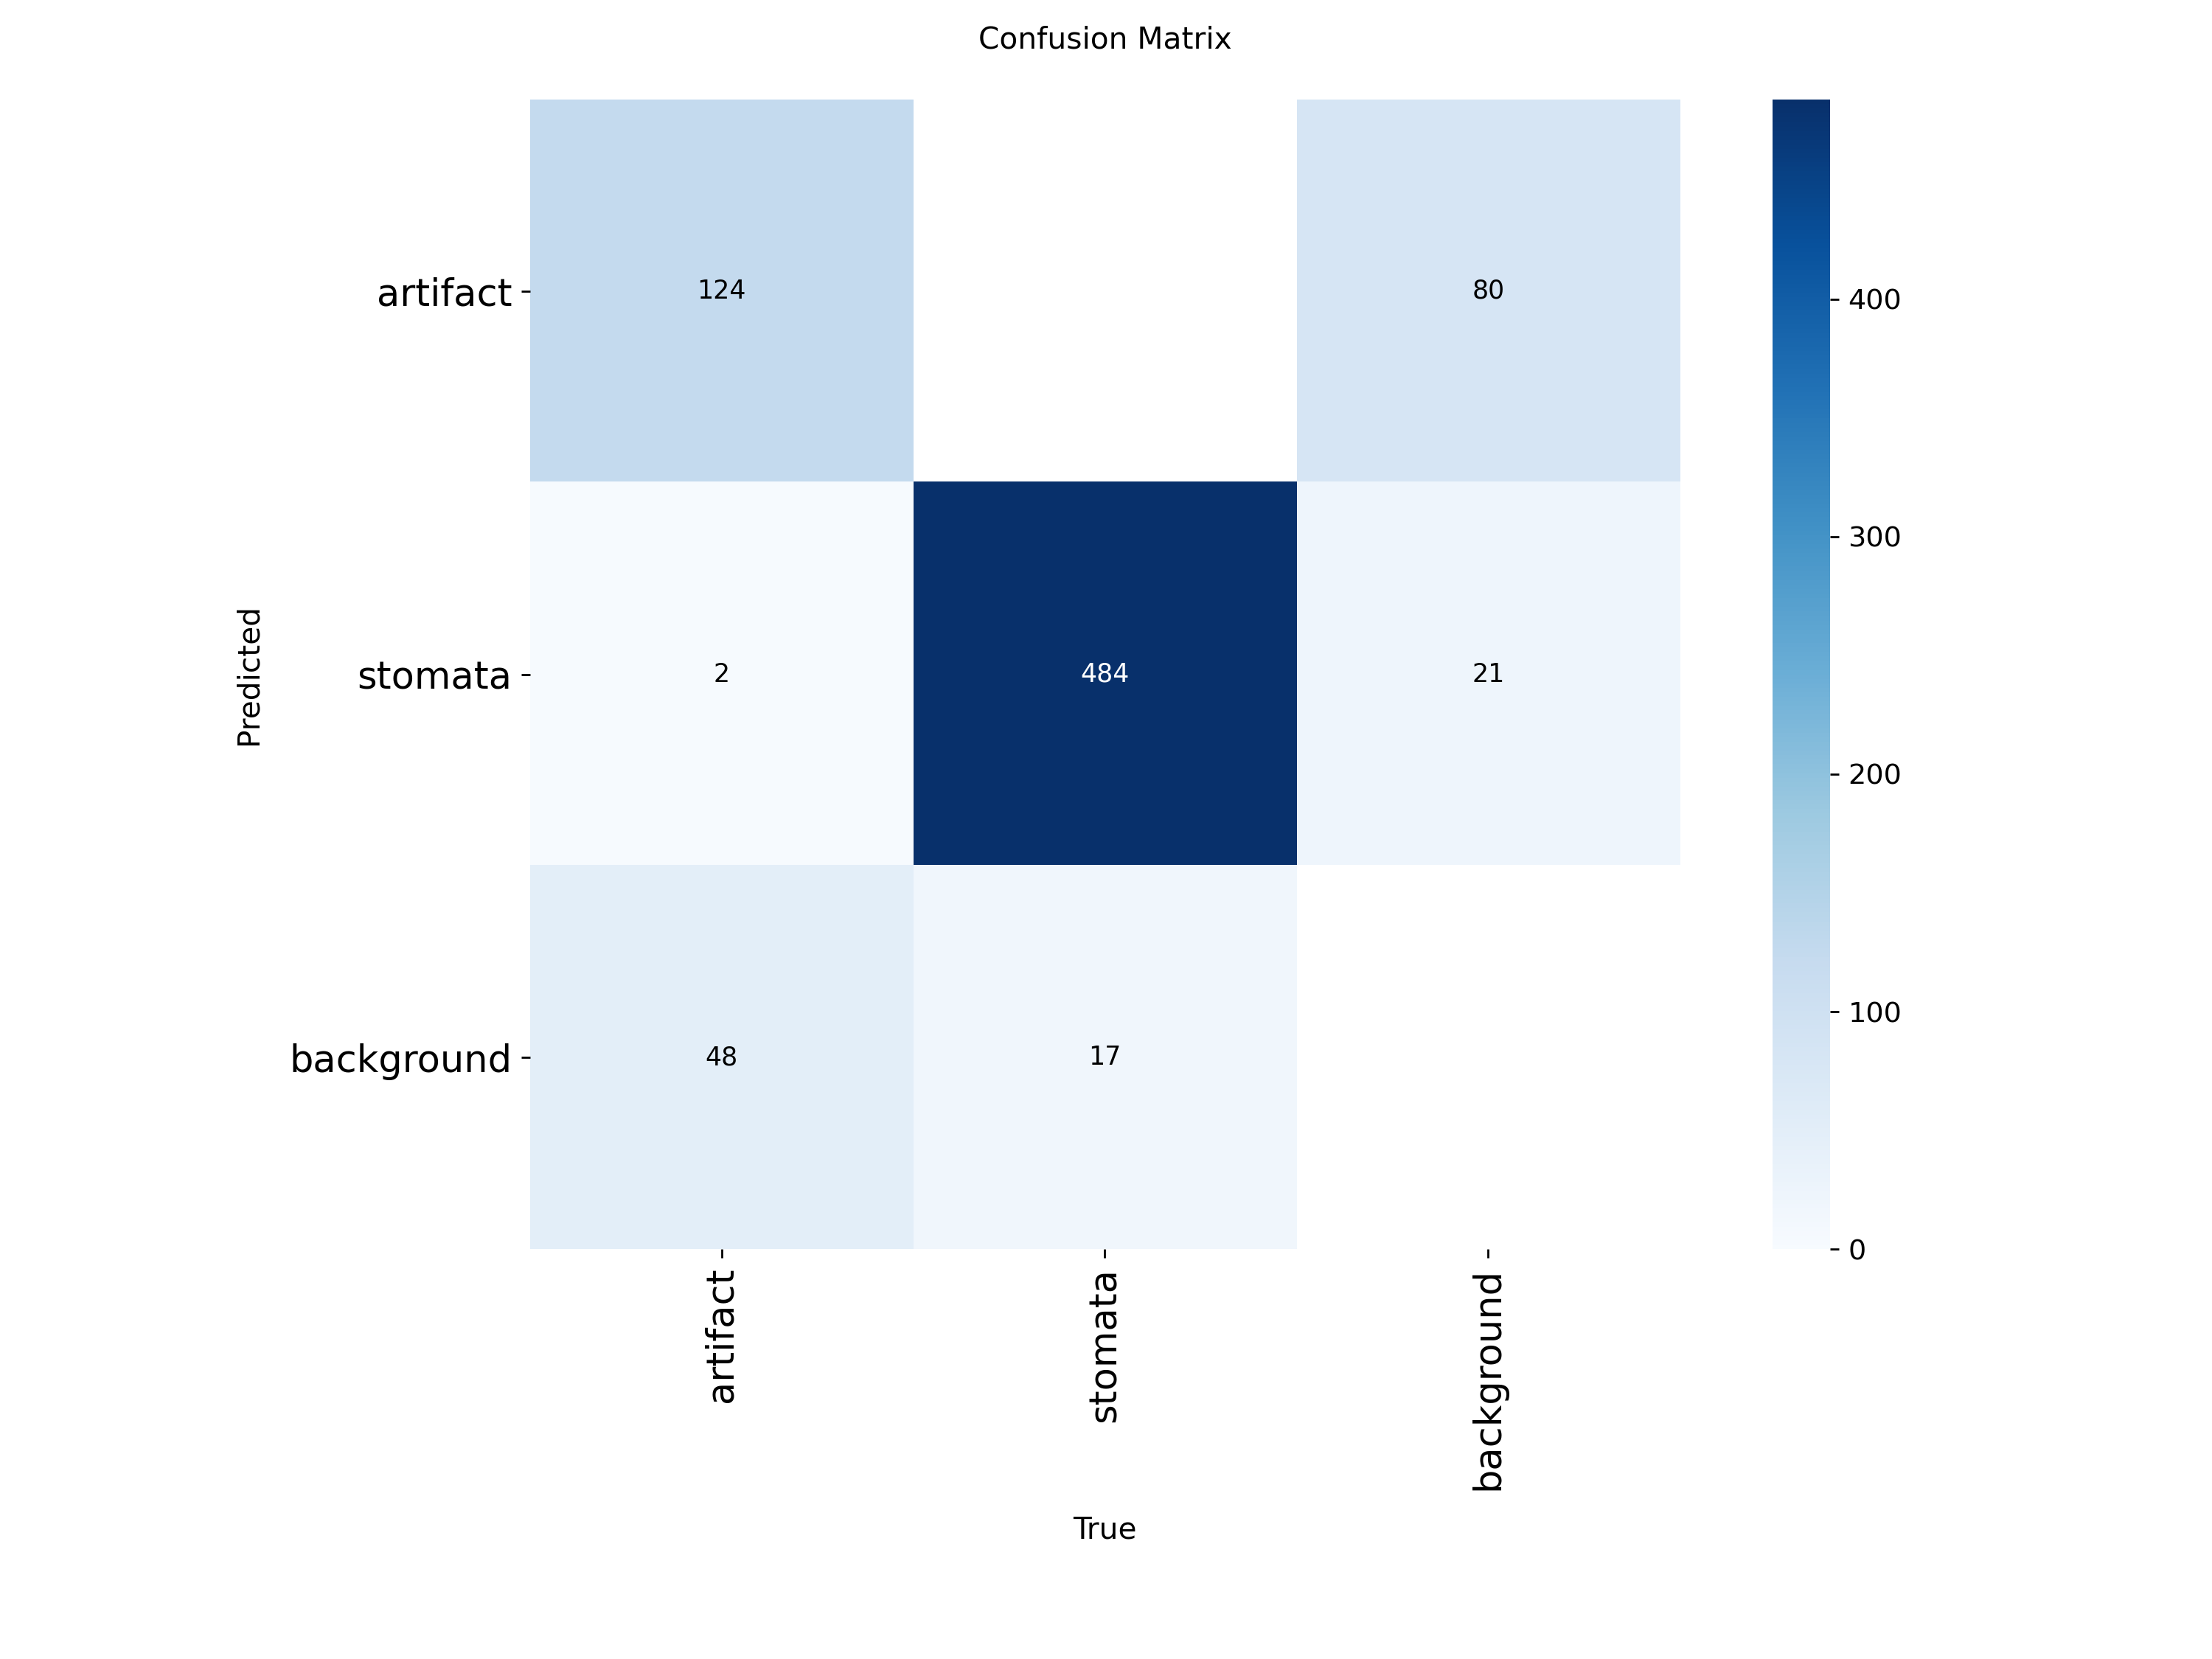

In [ ]:
RESULTS_PATH = '/content/stomata_training/run'

if os.path.exists(f'{RESULTS_PATH}/results.png'):
    print("📈 Training Curves:")
    display(Image(filename=f'{RESULTS_PATH}/results.png', width=900))

if os.path.exists(f'{RESULTS_PATH}/confusion_matrix.png'):
    print("\n📊 Confusion Matrix:")
    display(Image(filename=f'{RESULTS_PATH}/confusion_matrix.png', width=600))

---
## 📈 Step 8: Evaluate Model

In [ ]:
BEST_MODEL = os.path.join(RESULTS_PATH, 'weights', 'best.pt')

if os.path.exists(BEST_MODEL):
    best_model = YOLO(BEST_MODEL)
    metrics = best_model.val(data=os.path.join(DATASET_PATH, 'data.yaml'))

    print("="*60)
    print("📊 MODEL PERFORMANCE")
    print("="*60)
    print(f"   Precision:  {metrics.box.mp:.3f}")
    print(f"   Recall:     {metrics.box.mr:.3f}")
    print(f"   mAP@50:     {metrics.box.map50:.3f}")
    print("="*60)

Ultralytics 8.4.14 🚀 Python-3.12.12 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2043.0±589.3 MB/s, size: 90.9 KB)
val: Scanning /content/Stomata-Detection-5/valid/labels.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 19.1Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 11, len(boxes) = 675. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.2it/s 3.4s
                   all         50        675      0.804      0.825      0.801      0.449
              artifact         43        174      0.659       0.69      0.635      0.287
               stomata         50    

---
## 🧪 Step 9: Test Detection (Stomata Only)

In [ ]:
print("🔬 Testing: Only STOMATA shown (artifacts filtered out)\n")

# Get stomata index from model
model_stomata_idx = None
for idx, name in best_model.names.items():
    if 'stomata' in name.lower():
        model_stomata_idx = idx
print(f"Model stomata index: {model_stomata_idx}")

test_path = os.path.join(DATASET_PATH, 'valid', 'images')
test_images = [f for f in os.listdir(test_path) if f.endswith(('.jpg', '.png'))][:4]

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
axes = axes.flatten()

for idx, img_name in enumerate(test_images):
    img = cv2.imread(os.path.join(test_path, img_name))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    results = best_model.predict(os.path.join(test_path, img_name), conf=0.20, verbose=False)

    count = 0
    for box in results[0].boxes:
        cls = int(box.cls[0].cpu().numpy())
        if cls == model_stomata_idx:  # Only stomata
            count += 1
            x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(img, str(count), (x1, y1-10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

    axes[idx].imshow(img)
    axes[idx].set_title(f'Stomata: {count}', fontsize=12)
    axes[idx].axis('off')

plt.suptitle('FINAL OUTPUT: Stomata Only (Artifacts Filtered)', fontsize=14)
plt.tight_layout()
plt.show()
print("\n✅ Only stomata shown! Artifacts filtered out.")

Output hidden; open in https://colab.research.google.com to view.

---
## 💾 Step 10: Save & Download

In [ ]:
# Save to Drive
timestamp = datetime.now().strftime('%Y%m%d_%H%M')
drive_folder = f'{SAVE_DIR}/model_{timestamp}'
os.makedirs(drive_folder, exist_ok=True)

shutil.copy(BEST_MODEL, os.path.join(drive_folder, 'best.pt'))
print(f"✅ Saved to: {drive_folder}")

✅ Saved to: /content/drive/MyDrive/Stomata_Models_V5.1/model_20260213_2218


In [ ]:
# Download
from google.colab import files
files.download(BEST_MODEL)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## ✅ Complete!

Your model is trained on both classes but will only count stomata.